# AURORA SCORE 2.0 | Dataset sintético y modelamiento de riesgo alternativo

**Proyecto académico — Gestión de Proyectos de Datos (SCY1102).**  
**Versión revisada:** un único escenario con 12% de prevalencia objetivo y Gradient Boosting como candidato oficial.

Este notebook desarrolla un prototipo académico para Vertex Financial Group (VFG). Se conserva la decisión tecnológica adoptada por el equipo: **Alternativa A — plataforma cloud-nativa gestionada**. El alcance de este archivo es el componente de datos, modelamiento y evaluación del riesgo alternativo.

> **Advertencia:** todos los registros, relaciones y etiquetas de este notebook son sintéticos. Los resultados permiten comparar algoritmos bajo supuestos controlados; no demuestran el desempeño que se obtendría en una cartera real y no deben utilizarse para aprobar, rechazar, fijar tasas ni gestionar créditos reales.

**Fuentes consideradas:** telecomunicaciones, servicios básicos, billeteras digitales, comercio electrónico y metadatos de la aplicación móvil. De acuerdo con la presentación de implementación del equipo, redes sociales y biometría quedan excluidas como predictores; la biometría se reserva para verificación de identidad y prevención de fraude. Los atributos demográficos, geográficos y laborales se conservan únicamente para auditoría de equidad.

## 0. Diseño experimental y decisiones metodológicas

1. Se generan **10.000 solicitudes sintéticas**. Para facilitar la comparación entre jurisdicciones, se distribuyen equitativamente entre Chile, Perú, Colombia y México. Es un supuesto experimental, no una estimación de la composición real de VFG.
2. Se simulan cinco fuentes contempladas en el alcance actualizado: telecomunicaciones, servicios básicos, billeteras digitales, comercio electrónico y aplicación móvil. Se priorizan variables justificables; no se crean 240 columnas solo para alcanzar una cifra.
3. Se utiliza **un único escenario de 12% de prevalencia objetivo**. Es un supuesto de experimentación, no una tasa observada de mora de VFG ni el equivalente a la pérdida monetaria esperada del caso financiero.
4. Para corregir la caída observada en la versión anterior, se recupera el **mecanismo probabilístico gradual** de la primera versión 2.0. Se mantienen señales continuas y una interacción moderada entre atrasos de telecomunicaciones y servicios básicos. No se conservan los umbrales fuertes añadidos en la iteración anterior.
5. País, edad, zona, género y sector laboral no se utilizan para generar la etiqueta ni para entrenar el score inicial. Se reservan para auditoría de subgrupos.
6. Los valores faltantes se introducen después de generar las etiquetas. La falta de información no se interpreta como cero ni como incumplimiento.
7. Se separan entrenamiento, validación y prueba (60% / 20% / 20%). La imputación, el ajuste de hiperparámetros y la selección del umbral se realizan sin utilizar el conjunto de prueba.
8. **Regresión Logística** funciona como línea base interpretable y **Random Forest** como comparador. **Gradient Boosting es el candidato oficial del proyecto**, en coherencia con el caso de estudio. Se evalúan una versión base y otra optimizada; la variante oficial se elige únicamente con F1 de clase 1 en validación.
9. Se reportan Accuracy, Precision, Recall, F1 de clase 1, F1-macro, ROC-AUC, Average Precision (área bajo la curva Precision-Recall) y Brier score. La prueba se reserva para la evaluación final.


### ¿Qué significa el 12%?

Con 10.000 solicitudes, una prevalencia esperada del 12% equivale aproximadamente a 1.200 etiquetas positivas y 8.800 negativas. El conteo observado puede variar ligeramente por el muestreo Bernoulli. El 12% **no** se deriva de la pérdida esperada del 11% sobre la cartera colocada descrita en el caso: pérdida monetaria y porcentaje de clientes incumplidores son magnitudes distintas.

### Criterio para Gradient Boosting

El caso de estudio describe un ensamble de Gradient Boosting y la presentación de implementación del equipo propone comparar un baseline interpretable con boosting, calibración y umbrales. Por eso Gradient Boosting se declara candidato oficial de AURORA SCORE. Esta decisión de alineamiento con el caso no significa afirmar de antemano que será el algoritmo con mayor métrica en prueba. Los benchmarks se muestran y las diferencias se informan transparentemente.

In [ ]:
# Si falta alguna biblioteca en el entorno local, ejecutar:
# %pip install numpy pandas matplotlib seaborn scikit-learn

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, StratifiedKFold, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, brier_score_loss,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_curve, precision_recall_curve
)

SEED = 42
N_REGISTROS = 10_000
PAISES = ["Chile", "Perú", "Colombia", "México"]
PREVALENCIA_OBJETIVO = 0.12

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

print("Bibliotecas cargadas correctamente")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Registros planificados:", N_REGISTROS)
print("Prevalencia objetivo única:", f"{PREVALENCIA_OBJETIVO:.0%}")

Bibliotecas cargadas correctamente
NumPy: 2.4.6
Pandas: 2.2.3
Registros planificados: 10000
Prevalencia objetivo única: 12%


## 1. Diccionario de variables

El diccionario distingue entre disponibilidad de datos, comportamiento financiero, variables de monitoreo y atributos de auditoría. La etiqueta no está disponible al momento de la solicitud: se observa posteriormente durante la ventana de desempeño.

Las variables con uso “exploratorio” no deben pasar automáticamente al modelo. Su incorporación requiere una comparación documentada y revisión de posibles proxies.

In [ ]:
diccionario = [
    ("id_solicitud", "Identificador sintético único de la solicitud", "Texto", "Identificador; nunca predictor", "Sistema"),
    # Telecomunicaciones
    ("telco_pago_puntual_pct", "Proporción de pagos del servicio móvil realizados puntualmente en los últimos 12 meses", "Numérica 0–1", "Predictora inicial", "Telecomunicaciones"),
    ("telco_meses_atraso", "Cantidad de meses con atraso en pagos móviles durante los últimos 12 meses", "Entera 0–12", "Predictora inicial", "Telecomunicaciones"),
    ("telco_regularidad_recargas", "Regularidad temporal de las recargas de saldo", "Numérica 0–1", "Exploratoria", "Telecomunicaciones"),
    ("telco_antiguedad_linea_meses", "Antigüedad de la línea móvil en meses", "Entera", "Auditoría de proxy; excluida del score inicial", "Telecomunicaciones"),
    # Servicios básicos
    ("servicios_pago_puntual_pct", "Proporción de facturas de servicios básicos pagadas puntualmente", "Numérica 0–1", "Predictora inicial", "Servicios básicos"),
    ("servicios_tasa_atrasos", "Proporción de facturas con algún atraso", "Numérica 0–1", "Descriptiva; revisar redundancia", "Servicios básicos"),
    ("servicios_dias_atraso_mediana", "Mediana de días de atraso en facturas observadas", "Numérica, días", "Predictora inicial", "Servicios básicos"),
    ("servicios_facturas_observadas", "Cantidad de facturas observadas en la ventana de 12 meses", "Entera 0–12", "Calidad de datos; excluida del score", "Servicios básicos"),
    ("servicios_cobertura_pct", "Proporción de meses con información de servicios disponible", "Numérica 0–1", "Calidad de datos; excluida del score", "Servicios básicos"),
    # Billeteras digitales
    ("wallet_regularidad_mensual", "Regularidad de la actividad mensual de la billetera", "Numérica 0–1", "Predictora inicial", "Billeteras digitales"),
    ("wallet_tasa_reversiones", "Proporción de transacciones revertidas", "Numérica 0–1", "Predictora inicial, efecto débil", "Billeteras digitales"),
    ("wallet_ticket_mediano_relativo", "Ticket mediano relativo a una referencia sintética local", "Numérica positiva", "Descriptiva; excluida del score inicial", "Billeteras digitales"),
    ("wallet_meses_observados", "Cantidad de meses con información de billetera disponible", "Entera 0–12", "Calidad de datos; excluida del score", "Billeteras digitales"),
    # Comercio electrónico
    ("ecommerce_frecuencia_compras", "Cantidad promedio de compras mensuales", "Numérica no negativa", "Descriptiva", "Comercio electrónico"),
    ("ecommerce_ticket_mediano_relativo", "Ticket mediano relativo a una referencia sintética local", "Numérica positiva", "Descriptiva; excluida del score", "Comercio electrónico"),
    ("ecommerce_tasa_reclamos", "Proporción de compras con reclamos", "Numérica 0–1", "Exploratoria; no equivale a insolvencia", "Comercio electrónico"),
    ("ecommerce_tasa_devoluciones", "Proporción de compras devueltas", "Numérica 0–1", "Exploratoria; no equivale a insolvencia", "Comercio electrónico"),
    ("ecommerce_regularidad_compras", "Regularidad de compras durante la ventana de observación", "Numérica 0–1", "Exploratoria; potencial proxy de acceso", "Comercio electrónico"),
    # Aplicación móvil
    ("app_sesiones_mensuales", "Cantidad promedio de sesiones mensuales en la aplicación", "Numérica no negativa", "Monitoreo; excluida del score", "Aplicación móvil"),
    ("app_completitud_formulario", "Proporción de formularios iniciados que fueron completados", "Numérica 0–1", "Monitoreo; excluida del score", "Aplicación móvil"),
    ("app_tiempo_formulario_seg", "Tiempo mediano para completar un formulario", "Numérica positiva, segundos", "Monitoreo; excluida del score", "Aplicación móvil"),
    ("app_tasa_abandono", "Proporción de formularios iniciados que fueron abandonados", "Numérica 0–1", "Monitoreo; excluida del score", "Aplicación móvil"),
    # Contexto / auditoría
    ("pais", "País de operación de la solicitud", "Categórica", "Auditoría / segmentación", "Contexto"),
    ("grupo_edad", "Tramo etario sintético", "Categórica", "Auditoría; no predictor", "Auditoría"),
    ("zona_residencia", "Zona urbana o rural sintética", "Categórica", "Auditoría; no predictor", "Auditoría"),
    ("genero_auditoria", "Categoría de género sintética", "Categórica", "Auditoría; no predictor", "Auditoría"),
    ("sector_laboral", "Sector formal, informal o independiente", "Categórica", "Auditoría; no predictor", "Auditoría"),
    # Target
    ("incumplimiento_90d_12m", "Mora de 90 días o más durante los 12 meses posteriores al otorgamiento", "Binaria 0/1", "Variable objetivo", "Resultado observado"),
]

diccionario_df = pd.DataFrame(diccionario, columns=["Variable", "Descripción", "Tipo", "Uso previsto", "Fuente / grupo"])
display(diccionario_df)
print("Campos documentados:", len(diccionario_df), "(incluye ID y variable objetivo)")
print("Variables de fuentes y auditoría:", len(diccionario_df) - 2, "(excluye ID y target)")

,Variable,Descripción,Tipo,Uso previsto,Fuente / grupo
0,id_solicitud,Identificador sintético único de la solicitud,Texto,Identificador; nunca predictor,Sistema
1,telco_pago_puntual_pct,Proporción de pagos del servicio móvil realiza...,Numérica 0–1,Predictora inicial,Telecomunicaciones
2,telco_meses_atraso,Cantidad de meses con atraso en pagos móviles ...,Entera 0–12,Predictora inicial,Telecomunicaciones
3,telco_regularidad_recargas,Regularidad temporal de las recargas de saldo,Numérica 0–1,Exploratoria,Telecomunicaciones
4,telco_antiguedad_linea_meses,Antigüedad de la línea móvil en meses,Entera,Auditoría de proxy; excluida del score inicial,Telecomunicaciones
5,servicios_pago_puntual_pct,Proporción de facturas de servicios básicos pa...,Numérica 0–1,Predictora inicial,Servicios básicos
6,servicios_tasa_atrasos,Proporción de facturas con algún atraso,Numérica 0–1,Descriptiva; revisar redundancia,Servicios básicos
7,servicios_dias_atraso_mediana,Mediana de días de atraso en facturas observadas,"Numérica, días",Predictora inicial,Servicios básicos
8,servicios_facturas_observadas,Cantidad de facturas observadas en la ventana ...,Entera 0–12,Calidad de datos; excluida del score,Servicios básicos
9,servicios_cobertura_pct,Proporción de meses con información de servici...,Numérica 0–1,Calidad de datos; excluida del score,Servicios básicos


Campos documentados: 29 (incluye ID y variable objetivo)
Variables de fuentes y auditoría: 27 (excluye ID y target)


## 2. Generación de características sintéticas

Se construyen perfiles de comportamiento a partir de factores latentes de estrés de pago y actividad digital. Los factores latentes permiten simular correlaciones entre variables, pero **no se entregan directamente al modelo**.

Las cinco fuentes simuladas corresponden al alcance actualizado del equipo. Las variables de la aplicación móvil se conservan para revisar calidad y experiencia, pero no se incluyen inicialmente en el score de solvencia. Los atributos de auditoría se generan independientemente del factor financiero latente para no introducir deliberadamente diferencias de riesgo por edad, género, país, zona o sector laboral.

Las distribuciones y porcentajes son supuestos de simulación; no describen la población real de VFG.

In [ ]:
def limitar_01(x):
    return np.clip(np.asarray(x, dtype=float), 0.0, 1.0)


def generar_caracteristicas_completas(n=10_000, seed=42):
    """Genera atributos sintéticos completos, antes de introducir valores faltantes."""
    rng = np.random.default_rng(seed)

    # Contexto: balance igual por país solo para facilitar evaluación comparativa.
    pais = np.resize(np.array(PAISES, dtype=object), n)
    rng.shuffle(pais)

    grupo_edad = rng.choice(
        ["18-24", "25-44", "45-59", "60+"],
        size=n, p=[0.18, 0.40, 0.25, 0.17]
    )
    zona_residencia = rng.choice(["Urbana", "Rural"], size=n, p=[0.72, 0.28])
    genero_auditoria = rng.choice(
        ["Mujer", "Hombre", "Otro / no informa"],
        size=n, p=[0.49, 0.47, 0.04]
    )
    sector_laboral = rng.choice(
        ["Formal", "Informal", "Independiente"],
        size=n, p=[0.48, 0.27, 0.25]
    )

    # Factores latentes para simular heterogeneidad financiera y digital.
    estres_pago = rng.normal(0, 1, n)
    actividad_digital = rng.normal(0, 1, n)

    # 1) Telecomunicaciones
    telco_pago = limitar_01(0.93 - 0.085 * estres_pago + rng.normal(0, 0.065, n))
    telco_atrasos_lambda = np.clip(np.exp(-1.25 + 0.55 * estres_pago), 0.04, 3.2)
    telco_meses_atraso = np.clip(rng.poisson(telco_atrasos_lambda), 0, 12)
    telco_regularidad = limitar_01(0.82 - 0.045 * estres_pago + rng.normal(0, 0.13, n))
    telco_antiguedad = np.clip(rng.gamma(shape=2.5, scale=18, size=n).round(), 1, 180).astype(int)

    # 2) Servicios básicos
    servicios_pago = limitar_01(0.93 - 0.095 * estres_pago + rng.normal(0, 0.06, n))
    servicios_atrasos = limitar_01(1 - servicios_pago + rng.normal(0, 0.025, n))
    servicios_dias = np.clip(
        2 + 8 * servicios_atrasos + 3 * np.maximum(estres_pago, 0) + rng.normal(0, 5, n),
        0, 90
    )
    prob_cobertura_servicios = np.clip(0.88 + rng.normal(0, 0.08, n), 0.45, 1.0)
    servicios_facturas = rng.binomial(12, prob_cobertura_servicios)
    servicios_cobertura = servicios_facturas / 12

    # 3) Billeteras digitales
    wallet_regularidad = limitar_01(0.84 - 0.08 * estres_pago + rng.normal(0, 0.085, n))
    wallet_reversiones = limitar_01(0.025 + 0.015 * np.maximum(estres_pago, 0) + rng.normal(0, 0.02, n))
    wallet_ticket = np.exp(rng.normal(0, 0.35, n))
    wallet_meses = rng.binomial(12, 0.80, n)

    # 4) Comercio electrónico
    ecommerce_frecuencia = rng.poisson(np.exp(1.10 + 0.22 * actividad_digital))
    ecommerce_ticket = np.exp(rng.normal(0, 0.40, n))
    ecommerce_reclamos = rng.beta(2, 30, n)
    ecommerce_devoluciones = rng.beta(2, 24, n)
    ecommerce_regularidad = limitar_01(0.76 - 0.035 * estres_pago + rng.normal(0, 0.14, n))

    # 5) Aplicación móvil: variables de experiencia / monitoreo, no de solvencia.
    app_sesiones = np.clip(rng.poisson(np.exp(np.log(14) + 0.28 * actividad_digital)), 0, 150)
    app_completitud = limitar_01(0.82 + rng.normal(0, 0.13, n))
    app_tiempo = np.clip(np.exp(rng.normal(np.log(160), 0.48, n)), 20, 1800)
    app_abandono = limitar_01(0.18 + rng.normal(0, 0.10, n))

    df = pd.DataFrame({
        "id_solicitud": [f"AUR-{i:06d}" for i in range(1, n + 1)],
        "pais": pais,
        "grupo_edad": grupo_edad,
        "zona_residencia": zona_residencia,
        "genero_auditoria": genero_auditoria,
        "sector_laboral": sector_laboral,
        "telco_pago_puntual_pct": telco_pago,
        "telco_meses_atraso": telco_meses_atraso,
        "telco_regularidad_recargas": telco_regularidad,
        "telco_antiguedad_linea_meses": telco_antiguedad,
        "servicios_pago_puntual_pct": servicios_pago,
        "servicios_tasa_atrasos": servicios_atrasos,
        "servicios_dias_atraso_mediana": servicios_dias,
        "servicios_facturas_observadas": servicios_facturas,
        "servicios_cobertura_pct": servicios_cobertura,
        "wallet_regularidad_mensual": wallet_regularidad,
        "wallet_tasa_reversiones": wallet_reversiones,
        "wallet_ticket_mediano_relativo": wallet_ticket,
        "wallet_meses_observados": wallet_meses,
        "ecommerce_frecuencia_compras": ecommerce_frecuencia,
        "ecommerce_ticket_mediano_relativo": ecommerce_ticket,
        "ecommerce_tasa_reclamos": ecommerce_reclamos,
        "ecommerce_tasa_devoluciones": ecommerce_devoluciones,
        "ecommerce_regularidad_compras": ecommerce_regularidad,
        "app_sesiones_mensuales": app_sesiones,
        "app_completitud_formulario": app_completitud,
        "app_tiempo_formulario_seg": app_tiempo,
        "app_tasa_abandono": app_abandono,
    })
    return df


base_completa = generar_caracteristicas_completas(N_REGISTROS, SEED)
print("Dimensiones de características completas:", base_completa.shape)
display(base_completa.head())

Dimensiones de características completas: (10000, 28)


,id_solicitud,pais,grupo_edad,zona_residencia,genero_auditoria,sector_laboral,telco_pago_puntual_pct,telco_meses_atraso,telco_regularidad_recargas,telco_antiguedad_linea_meses,servicios_pago_puntual_pct,servicios_tasa_atrasos,servicios_dias_atraso_mediana,servicios_facturas_observadas,servicios_cobertura_pct,wallet_regularidad_mensual,wallet_tasa_reversiones,wallet_ticket_mediano_relativo,wallet_meses_observados,ecommerce_frecuencia_compras,ecommerce_ticket_mediano_relativo,ecommerce_tasa_reclamos,ecommerce_tasa_devoluciones,ecommerce_regularidad_compras,app_sesiones_mensuales,app_completitud_formulario,app_tiempo_formulario_seg,app_tasa_abandono
0,AUR-000001,Chile,25-44,Urbana,Otro / no informa,Formal,0.738789,0,0.878272,66,0.731280,0.285281,5.528549,12,1.000000,0.681652,0.026654,0.965322,10,4,0.914576,0.153400,0.165330,0.753732,14,1.000000,99.373331,0.110866
1,AUR-000002,Chile,18-24,Rural,Mujer,Informal,0.890987,1,0.795325,35,0.833262,0.186653,3.398121,12,1.000000,0.827262,0.054244,0.878156,9,6,1.145920,0.098682,0.023548,0.767202,24,0.880905,414.516436,0.016798
2,AUR-000003,México,60+,Rural,Hombre,Informal,0.946662,0,0.710966,62,0.922581,0.121384,7.153891,8,0.666667,0.897919,0.055053,1.466244,9,3,0.947308,0.030575,0.066688,0.696062,9,0.942807,185.423722,0.119634
3,AUR-000004,Perú,60+,Urbana,Hombre,Informal,1.000000,0,0.784152,17,1.000000,0.005720,0.000000,10,0.833333,0.994316,0.003503,0.794467,9,4,1.939583,0.032614,0.021341,0.958603,16,0.647020,161.576489,0.248645
4,AUR-000005,México,25-44,Urbana,Hombre,Informal,0.820215,0,0.817928,95,1.000000,0.000000,1.555859,11,0.916667,0.844841,0.032122,1.728849,10,10,1.215163,0.088351,0.007829,0.883441,22,0.824105,91.539988,0.125316


## 3. Generación probabilística de la variable objetivo

La etiqueta se genera a partir de señales graduales de comportamiento de pago: puntualidad móvil, cantidad de meses con atraso, puntualidad de servicios básicos, días de atraso, regularidad de billetera, reversiones y regularidad de compras digitales. Se agrega una interacción **moderada** entre los atrasos de telecomunicaciones y los días de atraso de servicios básicos.

Esta función recupera el enfoque de la primera versión 2.0. No utiliza reglas duras para asignar directamente la clase 1; calcula una probabilidad y luego genera la etiqueta mediante una distribución Bernoulli. Esto permite que clientes con perfiles parecidos puedan obtener resultados distintos.

Los coeficientes, la interacción y el ruido son hipótesis explícitas del generador sintético, no relaciones empíricas ni causales demostradas. El intercepto se calibra para que la probabilidad media esperada sea 12%. Edad, género, país, zona y sector laboral no participan en la fórmula.

In [ ]:
def zscore_seguro(serie):
    x = np.asarray(serie, dtype=float)
    sd = np.std(x)
    if sd == 0 or not np.isfinite(sd):
        return np.zeros_like(x)
    return (x - np.mean(x)) / sd


def sigmoid(x):
    x = np.clip(np.asarray(x, dtype=float), -30, 30)
    return 1 / (1 + np.exp(-x))


def calibrar_intercepto(score, prevalencia_objetivo, iteraciones=100):
    """Busca b tal que la media de sigmoid(b + score) alcance la prevalencia deseada."""
    if not 0 < prevalencia_objetivo < 1:
        raise ValueError("La prevalencia objetivo debe estar entre 0 y 1.")
    inferior, superior = -25.0, 25.0
    for _ in range(iteraciones):
        medio = (inferior + superior) / 2
        if sigmoid(medio + score).mean() < prevalencia_objetivo:
            inferior = medio
        else:
            superior = medio
    return (inferior + superior) / 2


def calcular_senal_riesgo(df):
    """Señal latente sintética; no usa atributos de auditoría ni variables excluidas."""
    z_telco_pago = zscore_seguro(1 - df["telco_pago_puntual_pct"])
    z_telco_atrasos = zscore_seguro(df["telco_meses_atraso"])
    z_servicios_pago = zscore_seguro(1 - df["servicios_pago_puntual_pct"])
    z_servicios_dias = zscore_seguro(df["servicios_dias_atraso_mediana"])
    z_wallet_regularidad = zscore_seguro(1 - df["wallet_regularidad_mensual"])
    z_wallet_reversiones = zscore_seguro(df["wallet_tasa_reversiones"])
    z_ecommerce_regularidad = zscore_seguro(1 - df["ecommerce_regularidad_compras"])

    # Interacción no lineal moderada: atrasos simultáneos en más de una fuente.
    interaccion = np.maximum(z_servicios_dias, 0) * np.maximum(z_telco_atrasos, 0)

    return (
        0.80 * z_telco_pago
        + 0.25 * z_telco_atrasos
        + 0.95 * z_servicios_pago
        + 0.30 * z_servicios_dias
        + 0.50 * z_wallet_regularidad
        + 0.15 * z_wallet_reversiones
        + 0.12 * z_ecommerce_regularidad
        + 0.18 * interaccion
    )


def generar_etiqueta(df_completo, prevalencia_objetivo, seed=42, desviacion_ruido=0.85):
    """Devuelve etiquetas, probabilidades generadoras y el intercepto sintético."""
    rng = np.random.default_rng(seed)
    senal = calcular_senal_riesgo(df_completo)
    ruido = rng.normal(0, desviacion_ruido, len(df_completo))
    riesgo_latente = senal + ruido
    intercepto = calibrar_intercepto(riesgo_latente, prevalencia_objetivo)
    probabilidad = sigmoid(intercepto + riesgo_latente)
    etiqueta = rng.binomial(1, probabilidad)
    return etiqueta.astype(int), probabilidad, intercepto



# Un único escenario: prevalencia objetivo del 12%.
y_sintetica, probabilidades_generadoras, intercepto_sintetico = generar_etiqueta(
    base_completa,
    prevalencia_objetivo=PREVALENCIA_OBJETIVO,
    seed=SEED + int(PREVALENCIA_OBJETIVO * 100)
)

resumen_generacion = pd.DataFrame([{
    "Registros": len(base_completa),
    "Prevalencia objetivo": PREVALENCIA_OBJETIVO,
    "Probabilidad media generada": probabilidades_generadoras.mean(),
    "Prevalencia observada": y_sintetica.mean(),
    "Intercepto sintético": intercepto_sintetico,
    "Incumplimientos observados": int(y_sintetica.sum()),
    "No incumplimientos observados": int((y_sintetica == 0).sum()),
}])
display(resumen_generacion.round(4))

,Registros,Prevalencia objetivo,Probabilidad media generada,Prevalencia observada,Intercepto sintético,Incumplimientos observados,No incumplimientos observados
0,10000,0.12,0.12,0.1203,-3.6366,1203,8797


## 4. Introducción controlada de datos faltantes

Los valores faltantes se introducen **después** de crear la etiqueta a partir de las características completas. Así se evita que la ausencia de una fuente se convierta artificialmente en una señal directa de incumplimiento.

Se preparan dos copias de la misma población sintética:

- **Cobertura uniforme:** ausencia aleatoria con tasas similares entre grupos.
- **Cobertura desigual (prueba de estrés):** menor disponibilidad hipotética de algunas fuentes para zona rural y personas de 60 años o más.

La versión con cobertura desigual se usa únicamente para la prueba de estrés posterior. El entrenamiento principal se realiza sobre cobertura uniforme. Las tasas de ausencia son supuestos experimentales, no mediciones reales de los cuatro países.

In [ ]:
def aplicar_faltantes(df_completo, seed=42, cobertura_desigual=False):
    rng = np.random.default_rng(seed)
    df = df_completo.copy()
    rural = (df["zona_residencia"].to_numpy() == "Rural").astype(float)
    mayor = (df["grupo_edad"].to_numpy() == "60+").astype(float)

    tasas_base = {
        "telco_pago_puntual_pct": 0.025,
        "telco_meses_atraso": 0.015,
        "telco_regularidad_recargas": 0.035,
        "servicios_pago_puntual_pct": 0.045,
        "servicios_tasa_atrasos": 0.045,
        "servicios_dias_atraso_mediana": 0.045,
        "wallet_regularidad_mensual": 0.060,
        "wallet_tasa_reversiones": 0.060,
        "wallet_ticket_mediano_relativo": 0.070,
        "ecommerce_frecuencia_compras": 0.055,
        "ecommerce_ticket_mediano_relativo": 0.055,
        "ecommerce_tasa_reclamos": 0.055,
        "ecommerce_tasa_devoluciones": 0.055,
        "ecommerce_regularidad_compras": 0.055,
        "app_sesiones_mensuales": 0.045,
        "app_completitud_formulario": 0.045,
        "app_tiempo_formulario_seg": 0.045,
        "app_tasa_abandono": 0.045,
    }

    for col, tasa in tasas_base.items():
        prob = np.full(len(df), tasa, dtype=float)
        if cobertura_desigual:
            if col.startswith("servicios_"):
                prob = prob + 0.12 * rural + 0.05 * mayor
            elif col.startswith("wallet_"):
                prob = prob + 0.10 * rural + 0.07 * mayor
            elif col.startswith("ecommerce_"):
                prob = prob + 0.07 * rural
            elif col.startswith("app_"):
                prob = prob + 0.10 * rural + 0.08 * mayor
        prob = np.clip(prob, 0, 0.45)
        mascara = rng.random(len(df)) < prob
        df.loc[mascara, col] = np.nan

    return df


base_uniforme = aplicar_faltantes(base_completa, seed=SEED + 500, cobertura_desigual=False)
base_cobertura_desigual = aplicar_faltantes(base_completa, seed=SEED + 501, cobertura_desigual=True)

datos_12 = base_uniforme.copy()
datos_12["incumplimiento_90d_12m"] = y_sintetica

datasets = {"12pct": datos_12}

print("Dimensiones del dataset único:", datos_12.shape)
print("Valores faltantes totales:", int(datos_12.isna().sum().sum()))
print("Prevalencia observada:", f"{datos_12['incumplimiento_90d_12m'].mean():.2%}")
display(datos_12.head())

Dimensiones del dataset único: (10000, 29)
Valores faltantes totales: 8485
Prevalencia observada: 12.03%


,id_solicitud,pais,grupo_edad,zona_residencia,genero_auditoria,sector_laboral,telco_pago_puntual_pct,telco_meses_atraso,telco_regularidad_recargas,telco_antiguedad_linea_meses,servicios_pago_puntual_pct,servicios_tasa_atrasos,servicios_dias_atraso_mediana,servicios_facturas_observadas,servicios_cobertura_pct,wallet_regularidad_mensual,wallet_tasa_reversiones,wallet_ticket_mediano_relativo,wallet_meses_observados,ecommerce_frecuencia_compras,ecommerce_ticket_mediano_relativo,ecommerce_tasa_reclamos,ecommerce_tasa_devoluciones,ecommerce_regularidad_compras,app_sesiones_mensuales,app_completitud_formulario,app_tiempo_formulario_seg,app_tasa_abandono,incumplimiento_90d_12m
0,AUR-000001,Chile,25-44,Urbana,Otro / no informa,Formal,0.738789,0.0,0.878272,66,0.731280,0.285281,5.528549,12,1.000000,0.681652,0.026654,0.965322,10,4.0,NaN,0.153400,0.165330,0.753732,14.0,1.000000,99.373331,0.110866,1
1,AUR-000002,Chile,18-24,Rural,Mujer,Informal,0.890987,1.0,0.795325,35,0.833262,0.186653,3.398121,12,1.000000,0.827262,0.054244,NaN,9,6.0,1.145920,0.098682,0.023548,0.767202,24.0,0.880905,414.516436,0.016798,0
2,AUR-000003,México,60+,Rural,Hombre,Informal,NaN,0.0,NaN,62,0.922581,NaN,7.153891,8,0.666667,0.897919,0.055053,1.466244,9,3.0,0.947308,0.030575,0.066688,0.696062,9.0,0.942807,185.423722,0.119634,0
3,AUR-000004,Perú,60+,Urbana,Hombre,Informal,1.000000,0.0,0.784152,17,1.000000,0.005720,0.000000,10,0.833333,0.994316,0.003503,0.794467,9,4.0,1.939583,NaN,NaN,0.958603,16.0,NaN,161.576489,0.248645,0
4,AUR-000005,México,25-44,Urbana,Hombre,Informal,0.820215,0.0,0.817928,95,1.000000,0.000000,1.555859,11,0.916667,0.844841,0.032122,1.728849,10,10.0,1.215163,0.088351,0.007829,0.883441,22.0,0.824105,91.539988,0.125316,0


## 5. Exploración de datos (EDA)

Se revisan tipos de datos, duplicados, distribución de la variable objetivo, estadísticas descriptivas y valores faltantes. La exploración permite verificar que el dataset tenga dimensiones esperadas y que la clase minoritaria esté representada.

La proporción observada puede no ser exactamente 12% porque las etiquetas se generan probabilísticamente. Se reportan tanto el objetivo de generación como la prevalencia real del dataset; **no se cambian etiquetas para forzar un conteo exacto**.

Dimensiones: (10000, 29)
Duplicados por ID: 0
Duplicados exactos: 0
Prevalencia objetivo: 12.00%
Prevalencia observada: 12.03%

Tipos de datos:


,dtype
id_solicitud,object
pais,object
grupo_edad,object
zona_residencia,object
genero_auditoria,object
sector_laboral,object
telco_pago_puntual_pct,float64
telco_meses_atraso,float64
telco_regularidad_recargas,float64
telco_antiguedad_linea_meses,int64



Resumen estadístico:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_solicitud,10000,10000,AUR-000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pais,10000,4,Chile,2500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
grupo_edad,10000,4,25-44,3934,NaN,NaN,NaN,NaN,NaN,NaN,NaN
zona_residencia,10000,2,Urbana,7113,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genero_auditoria,10000,3,Mujer,4862,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sector_laboral,10000,3,Formal,4714,NaN,NaN,NaN,NaN,NaN,NaN,NaN
telco_pago_puntual_pct,9744.0,NaN,NaN,NaN,0.914278,0.084234,0.519144,0.858329,0.931047,1.0,1.0
telco_meses_atraso,9863.0,NaN,NaN,NaN,0.326067,0.607812,0.0,0.0,0.0,1.0,7.0
telco_regularidad_recargas,9667.0,NaN,NaN,NaN,0.811989,0.126516,0.288498,0.724842,0.818325,0.911388,1.0
telco_antiguedad_linea_meses,10000.0,NaN,NaN,NaN,45.0763,28.901526,1.0,24.0,39.0,60.0,180.0



Valores faltantes:


,faltantes,porcentaje
wallet_regularidad_mensual,662,6.62
wallet_ticket_mediano_relativo,658,6.58
wallet_tasa_reversiones,621,6.21
ecommerce_ticket_mediano_relativo,572,5.72
ecommerce_frecuencia_compras,551,5.51
ecommerce_regularidad_compras,548,5.48
ecommerce_tasa_devoluciones,544,5.44
ecommerce_tasa_reclamos,521,5.21
servicios_dias_atraso_mediana,460,4.60
app_tiempo_formulario_seg,458,4.58


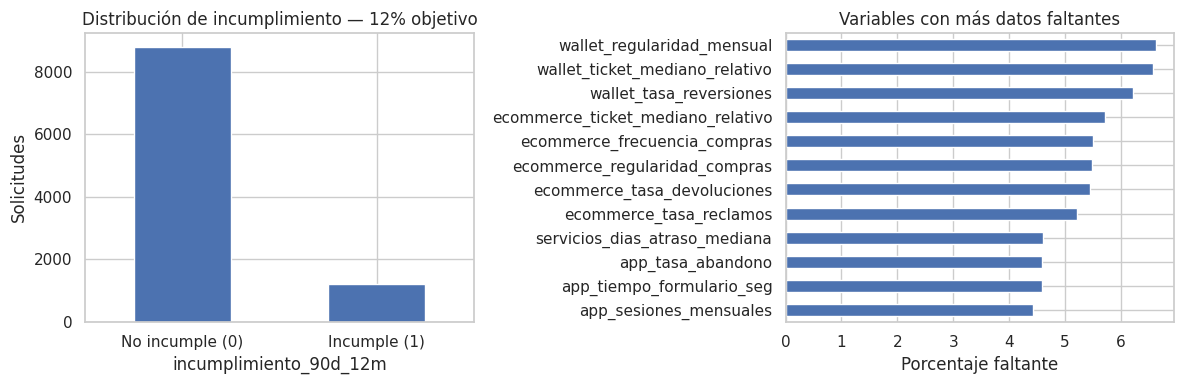

In [ ]:
TARGET = "incumplimiento_90d_12m"

print("Dimensiones:", datos_12.shape)
print("Duplicados por ID:", datos_12["id_solicitud"].duplicated().sum())
print("Duplicados exactos:", datos_12.duplicated().sum())
print("Prevalencia objetivo:", f"{PREVALENCIA_OBJETIVO:.2%}")
print("Prevalencia observada:", f"{datos_12[TARGET].mean():.2%}")
print("\nTipos de datos:")
display(datos_12.dtypes.to_frame("dtype"))
print("\nResumen estadístico:")
display(datos_12.describe(include="all").T)

reporte_faltantes = pd.DataFrame({
    "faltantes": datos_12.isna().sum(),
    "porcentaje": (datos_12.isna().mean() * 100).round(2)
}).sort_values("porcentaje", ascending=False)
print("\nValores faltantes:")
display(reporte_faltantes.head(20))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
datos_12[TARGET].value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set_title("Distribución de incumplimiento — 12% objetivo")
axes[0].set_xticks([0, 1], ["No incumple (0)", "Incumple (1)"], rotation=0)
axes[0].set_ylabel("Solicitudes")
reporte_faltantes["porcentaje"].head(12).sort_values().plot.barh(ax=axes[1])
axes[1].set_title("Variables con más datos faltantes")
axes[1].set_xlabel("Porcentaje faltante")
plt.tight_layout()
plt.show()


### Distribución observada de la variable objetivo

La siguiente tabla resume el único dataset que se utilizará: el escenario con prevalencia objetivo del 12%. La clase 1 corresponde a incumplimiento de 90 días o más durante los 12 meses posteriores al otorgamiento.

## 6. Selección de variables predictoras

Se parte de seis indicadores principales asociados al cumplimiento de pagos y se añaden dos variables exploratorias de estabilidad de recargas y regularidad de compras. Estas dos últimas se incluyen en el conjunto ampliado porque el generador de etiquetas las utiliza como señales graduales; su aporte también se revisa con una prueba de ablación.

Se excluyen del score las variables demográficas, geográficas y laborales, así como antigüedad de línea, volumen de actividad, valores de tickets y metadatos de uso de la aplicación. Estas variables pueden tener utilidad descriptiva o de auditoría, pero no se incorporan automáticamente a la decisión crediticia.

Las variables se revisan también por redundancia. En particular, tasa de atrasos y puntualidad de servicios pueden contener información complementaria o parcialmente redundante; se evita introducir ambas en el conjunto inicial.

Predictores principales:
 • telco_pago_puntual_pct
 • telco_meses_atraso
 • servicios_pago_puntual_pct
 • servicios_dias_atraso_mediana
 • wallet_regularidad_mensual
 • wallet_tasa_reversiones

Predictores exploratorios incluidos en la comparación:
 • telco_regularidad_recargas
 • ecommerce_regularidad_compras

Total de predictores del modelo: 8
Atributos de auditoría excluidos del entrenamiento: ['pais', 'grupo_edad', 'zona_residencia', 'genero_auditoria', 'sector_laboral']


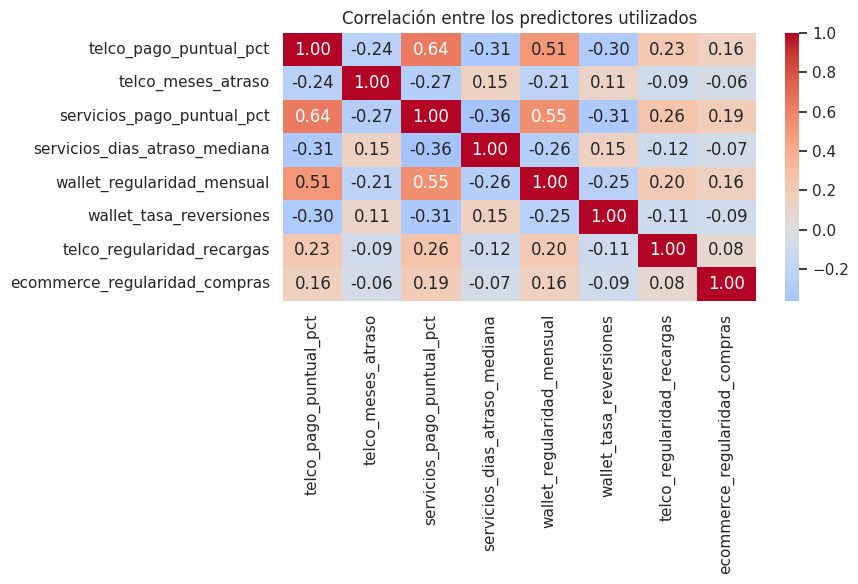

In [ ]:
FEATURES_CORE = [
    "telco_pago_puntual_pct",
    "telco_meses_atraso",
    "servicios_pago_puntual_pct",
    "servicios_dias_atraso_mediana",
    "wallet_regularidad_mensual",
    "wallet_tasa_reversiones",
]

FEATURES_EXPLORATORIAS = [
    "telco_regularidad_recargas",
    "ecommerce_regularidad_compras",
]

FEATURES_EXTENDED = FEATURES_CORE + FEATURES_EXPLORATORIAS
# Conjunto usado por todos los algoritmos para que la comparación sea equivalente.
FEATURES_MODELO = FEATURES_EXTENDED

COLUMNAS_AUDITORIA = [
    "pais", "grupo_edad", "zona_residencia", "genero_auditoria", "sector_laboral"
]

print("Predictores principales:")
for c in FEATURES_CORE:
    print(" •", c)
print("\nPredictores exploratorios incluidos en la comparación:")
for c in FEATURES_EXPLORATORIAS:
    print(" •", c)
print("\nTotal de predictores del modelo:", len(FEATURES_MODELO))
print("Atributos de auditoría excluidos del entrenamiento:", COLUMNAS_AUDITORIA)

plt.figure(figsize=(9, 6))
sns.heatmap(datos_12[FEATURES_MODELO].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación entre los predictores utilizados")
plt.tight_layout()
plt.show()

## 7. División entrenamiento / validación / prueba

Se utiliza una división estratificada 60% / 20% / 20% para conservar aproximadamente la prevalencia en las tres particiones. La semilla fija permite reproducir el experimento.

- **Entrenamiento:** ajusta imputadores y modelos, y participa en la validación cruzada para buscar hiperparámetros.
- **Validación:** selecciona el umbral de clasificación y permite escoger entre Gradient Boosting base y optimizado.
- **Prueba:** se reserva para una evaluación final, después de fijar el modelo y el umbral.

La estratificación es apropiada para esta simulación estática. En una cartera real, la evaluación debería ser temporal: entrenar con solicitudes antiguas y evaluar con cohortes posteriores.

In [ ]:
y = datos_12[TARGET].astype(int)

indices_train_val, indices_test = train_test_split(
    datos_12.index,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

indices_train, indices_val = train_test_split(
    indices_train_val,
    test_size=0.25,  # 25% del 80% = 20% del total
    random_state=SEED + 1,
    stratify=y.loc[indices_train_val]
)

X_train = datos_12.loc[indices_train, FEATURES_MODELO].copy()
y_train = y.loc[indices_train].copy()
X_val = datos_12.loc[indices_val, FEATURES_MODELO].copy()
y_val = y.loc[indices_val].copy()
X_test = datos_12.loc[indices_test, FEATURES_MODELO].copy()
y_test = y.loc[indices_test].copy()

particiones = pd.DataFrame({
    "Partición": ["Entrenamiento", "Validación", "Prueba"],
    "Registros": [len(y_train), len(y_val), len(y_test)],
    "Prevalencia": [y_train.mean(), y_val.mean(), y_test.mean()],
    "Incumplimientos": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
})
display(particiones.style.format({"Prevalencia": "{:.2%}"}))

assert set(indices_train).isdisjoint(set(indices_val))
assert set(indices_train).isdisjoint(set(indices_test))
assert set(indices_val).isdisjoint(set(indices_test))
print("Validación correcta: las tres particiones son independientes.")

,Partición,Registros,Prevalencia,Incumplimientos
0,Entrenamiento,6000,12.03%,722
1,Validación,2000,12.00%,240
2,Prueba,2000,12.05%,241


Validación correcta: las tres particiones son independientes.


## 8. Preprocesamiento, línea base y modelos candidatos

El imputador de mediana se ajusta dentro del pipeline y aprende exclusivamente a partir de entrenamiento. La regresión logística también utiliza estandarización; los modelos de árboles no la necesitan.

Se comparan cinco modelos:

1. Regresión Logística sin ponderación: línea base interpretable.
2. Regresión Logística balanceada: permite observar el efecto de ponderar la clase minoritaria.
3. Random Forest balanceado: modelo de árboles de comparación.
4. Gradient Boosting base: configuración de referencia.
5. Gradient Boosting optimizado: búsqueda reproducible de seis configuraciones mediante validación cruzada estratificada de tres folds.

La búsqueda de Gradient Boosting utiliza Average Precision como criterio de comparación de probabilidades. Luego, para cada modelo, el umbral que maximiza F1 de la clase 1 se selecciona usando únicamente validación. En caso de empate, se prioriza recall y después precision.

**Comparación justa:** todos los algoritmos utilizan las mismas ocho variables predictoras, los mismos índices de entrenamiento/validación/prueba y el mismo procedimiento para seleccionar el umbral. La ponderación de clases, cuando corresponde, se calcula únicamente con `y_train`. No se balancean validación ni prueba.

In [ ]:
def crear_pipeline(modelo, escalar=False):
    pasos = [("imputador", SimpleImputer(strategy="median"))]
    if escalar:
        pasos.append(("escalador", StandardScaler()))
    pasos.append(("modelo", modelo))
    return Pipeline(pasos)


def seleccionar_umbral_f1(y_real, probabilidades, umbrales=None):
    """Selecciona umbral por F1 de clase 1 usando solo validación."""
    if umbrales is None:
        umbrales = np.linspace(0.05, 0.80, 151)
    candidatos = []
    for umbral in umbrales:
        pred = (np.asarray(probabilidades) >= umbral).astype(int)
        f1 = f1_score(y_real, pred, zero_division=0)
        recall = recall_score(y_real, pred, zero_division=0)
        precision = precision_score(y_real, pred, zero_division=0)
        candidatos.append((f1, recall, precision, umbral))
    mejor = max(candidatos, key=lambda x: (x[0], x[1], x[2]))
    return float(mejor[3]), float(mejor[0])


def calcular_metricas(y_real, probabilidades, umbral=0.5):
    pred = (np.asarray(probabilidades) >= umbral).astype(int)
    return {
        "umbral": float(umbral),
        "accuracy": accuracy_score(y_real, pred),
        "balanced_accuracy": balanced_accuracy_score(y_real, pred),
        "precision_clase_1": precision_score(y_real, pred, zero_division=0),
        "recall_clase_1": recall_score(y_real, pred, zero_division=0),
        "f1_clase_1": f1_score(y_real, pred, zero_division=0),
        "f1_macro": f1_score(y_real, pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_real, probabilidades),
        "pr_auc_average_precision": average_precision_score(y_real, probabilidades),
        "brier": brier_score_loss(y_real, probabilidades),
    }


modelos_entrenados = {}
probabilidades_val = {}
probabilidades_test = {}
umbrales_modelos = {}
resultados_modelos = []

# Benchmarks: Regresión Logística y Random Forest.
modelos_base = {
    "Regresión logística — sin balanceo": (
        crear_pipeline(LogisticRegression(max_iter=3000, random_state=SEED), escalar=True),
        False,
    ),
    "Regresión logística — balanceada": (
        crear_pipeline(LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED), escalar=True),
        False,
    ),
    "Random Forest — balanceado": (
        crear_pipeline(RandomForestClassifier(
            n_estimators=180,
            max_depth=6,
            min_samples_leaf=12,
            class_weight="balanced_subsample",
            random_state=SEED,
            n_jobs=-1,
        )),
        False,
    ),
}

for nombre, (pipeline, _) in modelos_base.items():
    pipeline.fit(X_train, y_train)
    p_val = pipeline.predict_proba(X_val)[:, 1]
    umbral, f1_val = seleccionar_umbral_f1(y_val, p_val)
    p_test = pipeline.predict_proba(X_test)[:, 1]
    m_test = calcular_metricas(y_test, p_test, umbral)

    modelos_entrenados[nombre] = pipeline
    probabilidades_val[nombre] = p_val
    probabilidades_test[nombre] = p_test
    umbrales_modelos[nombre] = umbral
    resultados_modelos.append({
        "Modelo": nombre,
        "Rol": "Benchmark",
        "F1 validación": f1_val,
        "Umbral validación": umbral,
        "Accuracy prueba": m_test["accuracy"],
        "Precision prueba": m_test["precision_clase_1"],
        "Recall prueba": m_test["recall_clase_1"],
        "F1 clase 1 prueba": m_test["f1_clase_1"],
        "F1-macro prueba": m_test["f1_macro"],
        "ROC-AUC prueba": m_test["roc_auc"],
        "PR-AUC prueba": m_test["pr_auc_average_precision"],
    })

# Gradient Boosting base: referencia sin búsqueda de hiperparámetros.
gb_base = crear_pipeline(GradientBoostingClassifier(
    n_estimators=120,
    learning_rate=0.04,
    max_depth=2,
    min_samples_leaf=25,
    subsample=0.85,
    random_state=SEED,
))
pesos_train = compute_sample_weight(class_weight="balanced", y=y_train)
gb_base.fit(X_train, y_train, modelo__sample_weight=pesos_train)

# Gradient Boosting optimizado: 6 configuraciones, 3 folds estratificados.
# La búsqueda ocurre solo dentro de entrenamiento; validation y test quedan fuera.
gb_pipeline = crear_pipeline(GradientBoostingClassifier(random_state=SEED))
parametros_gb = {
    "modelo__n_estimators": [80, 120, 160],
    "modelo__learning_rate": [0.03, 0.05],
    "modelo__max_depth": [1, 2],
    "modelo__min_samples_leaf": [20, 35],
    "modelo__subsample": [0.85],
}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=123)
busqueda_gb = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=parametros_gb,
    n_iter=6,
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    random_state=123,
    refit=True,
    return_train_score=False,
)
busqueda_gb.fit(X_train, y_train, modelo__sample_weight=pesos_train)
gb_optimizado = busqueda_gb.best_estimator_

print("Mejores hiperparámetros de Gradient Boosting:")
display(pd.Series(busqueda_gb.best_params_, name="Valor").to_frame())
print("Average Precision medio en validación cruzada:", round(busqueda_gb.best_score_, 4))

# Evaluar ambas variantes del Gradient Boosting con el mismo umbral de selección.
for nombre, pipeline in [
    ("Gradient Boosting — base", gb_base),
    ("Gradient Boosting — optimizado", gb_optimizado),
]:
    p_val = pipeline.predict_proba(X_val)[:, 1]
    umbral, f1_val = seleccionar_umbral_f1(y_val, p_val)
    p_test = pipeline.predict_proba(X_test)[:, 1]
    m_test = calcular_metricas(y_test, p_test, umbral)

    modelos_entrenados[nombre] = pipeline
    probabilidades_val[nombre] = p_val
    probabilidades_test[nombre] = p_test
    umbrales_modelos[nombre] = umbral
    resultados_modelos.append({
        "Modelo": nombre,
        "Rol": "Candidato oficial",
        "F1 validación": f1_val,
        "Umbral validación": umbral,
        "Accuracy prueba": m_test["accuracy"],
        "Precision prueba": m_test["precision_clase_1"],
        "Recall prueba": m_test["recall_clase_1"],
        "F1 clase 1 prueba": m_test["f1_clase_1"],
        "F1-macro prueba": m_test["f1_macro"],
        "ROC-AUC prueba": m_test["roc_auc"],
        "PR-AUC prueba": m_test["pr_auc_average_precision"],
    })

comparacion_modelos = pd.DataFrame(resultados_modelos).sort_values(
    "F1 validación", ascending=False
).reset_index(drop=True)
display(comparacion_modelos.round(4))

Mejores hiperparámetros de Gradient Boosting:


,Valor
modelo__subsample,0.85
modelo__n_estimators,160.00
modelo__min_samples_leaf,20.00
modelo__max_depth,2.00
modelo__learning_rate,0.05


Average Precision medio en validación cruzada: 0.6424


,Modelo,Rol,F1 validación,Umbral validación,Accuracy prueba,Precision prueba,Recall prueba,F1 clase 1 prueba,F1-macro prueba,ROC-AUC prueba,PR-AUC prueba
0,Random Forest — balanceado,Benchmark,0.6367,0.630,0.8970,0.5566,0.7137,0.6255,0.7829,0.9196,0.6635
1,Gradient Boosting — optimizado,Candidato oficial,0.6364,0.780,0.9130,0.6426,0.6266,0.6345,0.7925,0.9218,0.6787
2,Regresión logística — balanceada,Benchmark,0.6324,0.735,0.9105,0.6148,0.6888,0.6497,0.7992,0.9251,0.6933
3,Gradient Boosting — base,Candidato oficial,0.6278,0.765,0.9065,0.6071,0.6349,0.6207,0.7837,0.9224,0.6800
4,Regresión logística — sin balanceo,Benchmark,0.6250,0.255,0.9075,0.5993,0.7012,0.6463,0.7965,0.9253,0.6930


## 9. Designación del candidato oficial y evaluación final

La familia **Gradient Boosting** es el candidato oficial del proyecto por alineamiento con el caso de estudio. Para seleccionar la implementación concreta, se comparan Gradient Boosting base y optimizado y se elige la variante con mayor F1 de clase 1 en validación. El modelo y el umbral quedan fijados antes de consultar la evaluación final.

La tabla comparativa presenta también los resultados de prueba de los benchmarks para transparentar el desempeño relativo; esos resultados no se usan para elegir ni ajustar el modelo. Si Regresión Logística obtiene una métrica superior en prueba, se informa como hallazgo. No se oculta ni se altera el conjunto de datos para forzar una victoria de Gradient Boosting.

F1-macro se informa como complemento: promedia el F1 de ambas clases y puede verse favorecido por el buen desempeño de la clase mayoritaria. Por eso se presentan también precision, recall y matriz de confusión de la clase de incumplimiento.

CANDIDATO OFICIAL AURORA SCORE: Gradient Boosting — optimizado
F1 clase 1 en validación: 0.6364
Umbral fijado en validación: 0.78

Evaluación final en el conjunto de prueba:


,umbral,accuracy,balanced_accuracy,precision_clase_1,recall_clase_1,f1_clase_1,f1_macro,roc_auc,pr_auc_average_precision,brier
0,0.78,0.913,0.7894,0.6426,0.6266,0.6345,0.7925,0.9218,0.6787,0.1128


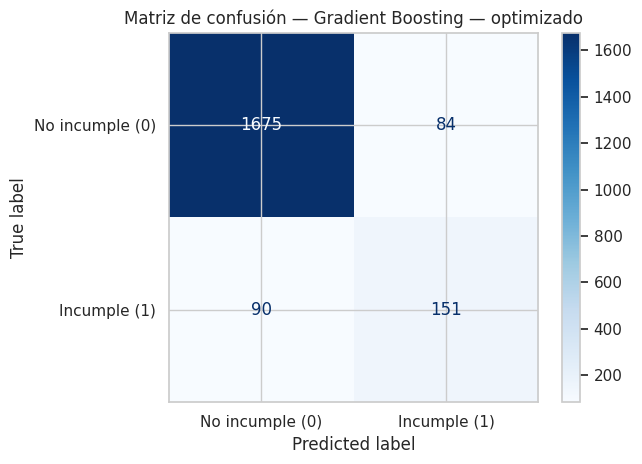

              precision    recall  f1-score   support

 No incumple       0.95      0.95      0.95      1759
    Incumple       0.64      0.63      0.63       241

    accuracy                           0.91      2000
   macro avg       0.80      0.79      0.79      2000
weighted avg       0.91      0.91      0.91      2000



In [ ]:
# Selección del candidato oficial: solo entre Gradient Boosting base y optimizado.
filas_gb = comparacion_modelos[
    comparacion_modelos["Modelo"].isin([
        "Gradient Boosting — base",
        "Gradient Boosting — optimizado",
    ])
].copy()

modelo_elegido_nombre = filas_gb.sort_values(
    ["F1 validación", "Modelo"], ascending=[False, True]
).iloc[0]["Modelo"]
modelo_elegido = modelos_entrenados[modelo_elegido_nombre]
umbral_elegido = umbrales_modelos[modelo_elegido_nombre]
p_val_elegido = probabilidades_val[modelo_elegido_nombre]
p_test_elegido = probabilidades_test[modelo_elegido_nombre]
pred_test_elegido = (p_test_elegido >= umbral_elegido).astype(int)
f1_val_elegido = f1_score(y_val, (p_val_elegido >= umbral_elegido).astype(int), zero_division=0)

print("CANDIDATO OFICIAL AURORA SCORE:", modelo_elegido_nombre)
print("F1 clase 1 en validación:", round(f1_val_elegido, 4))
print("Umbral fijado en validación:", round(umbral_elegido, 3))
print("\nEvaluación final en el conjunto de prueba:")
metricas_finales = calcular_metricas(y_test, p_test_elegido, umbral_elegido)
display(pd.DataFrame([metricas_finales]).round(4))

cm = confusion_matrix(y_test, pred_test_elegido, labels=[0, 1])
disp = ConfusionMatrixDisplay(cm, display_labels=["No incumple (0)", "Incumple (1)"])
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Matriz de confusión — {modelo_elegido_nombre}")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test, pred_test_elegido,
    target_names=["No incumple", "Incumple"],
    zero_division=0,
))

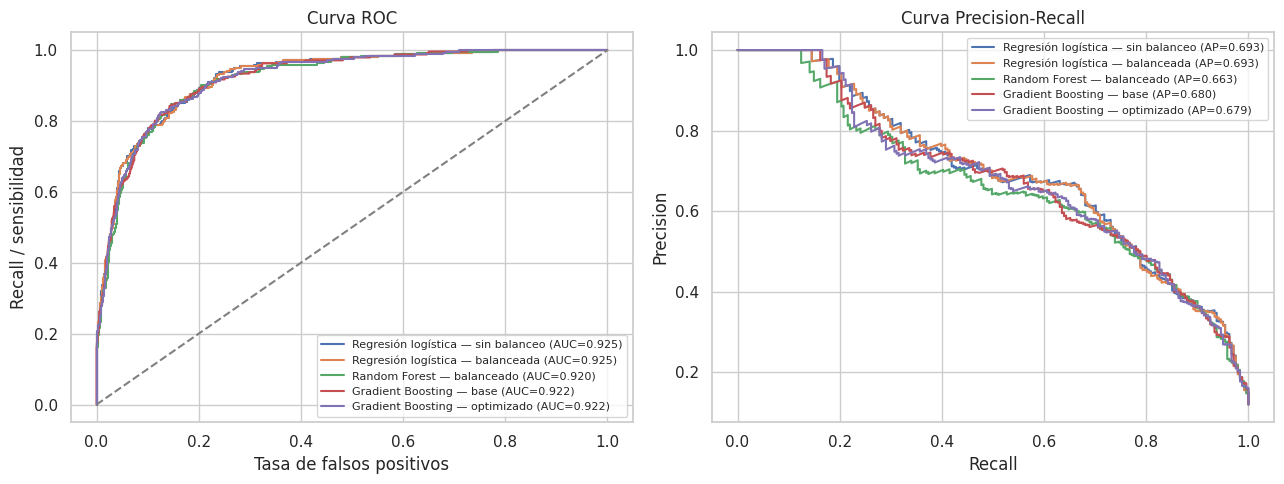

In [ ]:
# Curvas ROC y Precision-Recall para todos los modelos comparados.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for nombre, p_test in probabilidades_test.items():
    fpr, tpr, _ = roc_curve(y_test, p_test)
    precision, recall, _ = precision_recall_curve(y_test, p_test)
    auc_roc = roc_auc_score(y_test, p_test)
    ap = average_precision_score(y_test, p_test)
    axes[0].plot(fpr, tpr, label=f"{nombre} (AUC={auc_roc:.3f})")
    axes[1].plot(recall, precision, label=f"{nombre} (AP={ap:.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set(title="Curva ROC", xlabel="Tasa de falsos positivos", ylabel="Recall / sensibilidad")
axes[1].set(title="Curva Precision-Recall", xlabel="Recall", ylabel="Precision")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 10. Prueba de ablación: aporte de las variables exploratorias

Se compara el conjunto de seis variables principales con el conjunto ampliado de ocho variables. Ambos se entrenan con los hiperparámetros de la variante oficial de Gradient Boosting para aislar, en lo posible, el efecto de añadir `telco_regularidad_recargas` y `ecommerce_regularidad_compras`.

El umbral se vuelve a seleccionar en validación para cada conjunto de variables. La prueba ayuda a decidir si la complejidad adicional aporta valor. La conclusión debe considerar tanto las métricas como disponibilidad, estabilidad, interpretación y posible efecto de proxy.

In [ ]:
parametros_oficiales = modelo_elegido.named_steps["modelo"].get_params()
parametros_oficiales = {
    k: parametros_oficiales[k]
    for k in ["n_estimators", "learning_rate", "max_depth", "min_samples_leaf", "subsample"]
}


def entrenar_gb_ponderado(Xtr, ytr, columnas_features):
    estimador = GradientBoostingClassifier(random_state=SEED, **parametros_oficiales)
    pipe = crear_pipeline(estimador)
    pesos = compute_sample_weight(class_weight="balanced", y=ytr)
    pipe.fit(Xtr[columnas_features], ytr, modelo__sample_weight=pesos)
    return pipe


resultados_ablacion = []
modelos_ablacion = {}
for nombre, columnas in [
    ("Variables principales", FEATURES_CORE),
    ("Principales + exploratorias", FEATURES_EXTENDED),
]:
    pipe = entrenar_gb_ponderado(
        datos_12.loc[indices_train, columnas], y_train, columnas
    )
    p_val = pipe.predict_proba(datos_12.loc[indices_val, columnas])[:, 1]
    umbral, f1_val = seleccionar_umbral_f1(y_val, p_val)
    p_test = pipe.predict_proba(datos_12.loc[indices_test, columnas])[:, 1]
    m = calcular_metricas(y_test, p_test, umbral)
    resultados_ablacion.append({
        "Conjunto de variables": nombre,
        "Cantidad de variables": len(columnas),
        "F1 validación": f1_val,
        "Umbral validación": umbral,
        "Accuracy prueba": m["accuracy"],
        "Recall prueba": m["recall_clase_1"],
        "F1 clase 1 prueba": m["f1_clase_1"],
        "F1-macro prueba": m["f1_macro"],
        "PR-AUC prueba": m["pr_auc_average_precision"],
    })
    modelos_ablacion[nombre] = pipe

display(pd.DataFrame(resultados_ablacion).round(4))

,Conjunto de variables,Cantidad de variables,F1 validación,Umbral validación,Accuracy prueba,Recall prueba,F1 clase 1 prueba,F1-macro prueba,PR-AUC prueba
0,Variables principales,6,0.6351,0.68,0.8865,0.7510,0.6146,0.7740,0.6817
1,Principales + exploratorias,8,0.6364,0.78,0.9130,0.6266,0.6345,0.7925,0.6787


## 11. Interpretación del escenario único de prevalencia

Esta versión utiliza exclusivamente el escenario de **12% de prevalencia objetivo**. No se ejecutan escenarios alternativos de 8% ni 15%.

La función calibra la probabilidad promedio antes de muestrear las etiquetas. Por eso la proporción final observada puede variar ligeramente alrededor del 12%. No se duplican registros ni se reescriben etiquetas para forzar el porcentaje.

## 12. Auditoría de desempeño por subgrupos

Se utiliza el candidato oficial Gradient Boosting y el umbral elegido en validación. La auditoría compara recall, precision, tasa de falsos positivos y proporción de predicciones positivas por país, edad, zona, género y sector laboral.

Estos atributos no participan en el entrenamiento ni en la generación de la etiqueta. Se utilizan únicamente después del modelamiento para describir diferencias entre subgrupos. En datos sintéticos, las brechas no prueban discriminación real ni garantizan ausencia de sesgo; ilustran el tipo de revisión que deberá repetirse con datos reales, representativos y obtenidos lícitamente.

In [ ]:
def metricas_por_grupo(y_real, y_pred, grupos, nombre_grupo):
    filas = []
    tmp = pd.DataFrame({
        "y": np.asarray(y_real),
        "pred": np.asarray(y_pred),
        "grupo": np.asarray(grupos)
    })
    for grupo, parte in tmp.groupby("grupo", dropna=False):
        tn, fp, fn, tp = confusion_matrix(parte["y"], parte["pred"], labels=[0, 1]).ravel()
        filas.append({
            "Variable de auditoría": nombre_grupo,
            "Grupo": str(grupo),
            "N": len(parte),
            "Incumplimientos reales": int(parte["y"].sum()),
            "Recall": tp / (tp + fn) if (tp + fn) else np.nan,
            "Precision": tp / (tp + fp) if (tp + fp) else np.nan,
            "Tasa falsos positivos": fp / (fp + tn) if (fp + tn) else np.nan,
            "Predicción positiva": parte["pred"].mean(),
        })
    return filas


filas_auditoria = []
for columna in COLUMNAS_AUDITORIA:
    filas_auditoria.extend(metricas_por_grupo(
        y_test,
        pred_test_elegido,
        datos_12.loc[indices_test, columna],
        columna
    ))

auditoria_subgrupos = pd.DataFrame(filas_auditoria)
display(auditoria_subgrupos.round(3))

# Rango de recall por atributo (brecha descriptiva entre el mayor y menor grupo).
resumen_brechas = (
    auditoria_subgrupos.groupby("Variable de auditoría")["Recall"]
    .agg(minimo="min", maximo="max")
)
resumen_brechas["brecha_recall"] = resumen_brechas["maximo"] - resumen_brechas["minimo"]
display(resumen_brechas.round(3))

,Variable de auditoría,Grupo,N,Incumplimientos reales,Recall,Precision,Tasa falsos positivos,Predicción positiva
0,pais,Chile,481,59,0.627,0.755,0.028,0.102
1,pais,Colombia,485,67,0.627,0.677,0.048,0.128
2,pais,México,504,59,0.627,0.578,0.061,0.127
3,pais,Perú,530,56,0.625,0.583,0.053,0.113
4,grupo_edad,18-24,377,48,0.646,0.646,0.052,0.127
5,grupo_edad,25-44,788,99,0.606,0.638,0.049,0.119
6,grupo_edad,45-59,527,62,0.645,0.678,0.041,0.112
7,grupo_edad,60+,308,32,0.625,0.588,0.051,0.110
8,zona_residencia,Rural,566,73,0.575,0.618,0.053,0.120
9,zona_residencia,Urbana,1434,168,0.649,0.653,0.046,0.116


,minimo,maximo,brecha_recall
Variable de auditoría,,,
genero_auditoria,0.583,0.800,0.217
grupo_edad,0.606,0.646,0.040
pais,0.625,0.627,0.002
sector_laboral,0.619,0.630,0.011
zona_residencia,0.575,0.649,0.073


## 13. Prueba de estrés: cobertura de datos desigual

Se evalúa el mismo candidato oficial y el mismo conjunto de prueba cuando algunas fuentes tienen mayor proporción de valores faltantes para zona rural y personas de 60 años o más. Las etiquetas subyacentes y las características completas permanecen iguales; cambia únicamente la disponibilidad observada.

El experimento permite examinar si una cobertura desigual de fuentes afecta el desempeño o genera brechas entre subgrupos. No representa una estimación de cobertura real en Chile, Perú, Colombia o México.

In [ ]:
# Se conserva la misma muestra y las mismas etiquetas; solo aumenta la ausencia de algunas fuentes.
base_stress = aplicar_faltantes(base_completa, seed=SEED + 501, cobertura_desigual=True)
X_test_stress = base_stress.loc[indices_test, FEATURES_MODELO].copy()

p_test_stress = modelo_elegido.predict_proba(X_test_stress)[:, 1]
pred_test_stress = (p_test_stress >= umbral_elegido).astype(int)

metricas_uniforme = calcular_metricas(y_test, p_test_elegido, umbral_elegido)
metricas_stress = calcular_metricas(y_test, p_test_stress, umbral_elegido)
comparacion_stress = pd.DataFrame([
    {"Cobertura": "Uniforme", **metricas_uniforme},
    {"Cobertura": "Desigual (estrés)", **metricas_stress},
]).set_index("Cobertura")
display(comparacion_stress.round(4))

# Comparación de valores faltantes por zona y grupo etario en variables utilizadas.
resumen_faltantes_grupo = []
for col in FEATURES_MODELO:
    for variable_grupo in ["zona_residencia", "grupo_edad"]:
        tasas = base_stress.groupby(variable_grupo)[col].apply(lambda s: s.isna().mean())
        for grupo, tasa in tasas.items():
            resumen_faltantes_grupo.append({
                "Variable": col,
                "Segmentación": variable_grupo,
                "Grupo": grupo,
                "Faltantes (%)": tasa * 100,
            })

faltantes_grupo_df = pd.DataFrame(resumen_faltantes_grupo)
display(faltantes_grupo_df.round(2))

filas_stress_auditoria = []
for columna in ["zona_residencia", "grupo_edad"]:
    filas_stress_auditoria.extend(metricas_por_grupo(
        y_test, pred_test_stress, datos_12.loc[indices_test, columna], columna
    ))
auditoria_stress = pd.DataFrame(filas_stress_auditoria)
display(auditoria_stress.round(3))

,umbral,accuracy,balanced_accuracy,precision_clase_1,recall_clase_1,f1_clase_1,f1_macro,roc_auc,pr_auc_average_precision,brier
Cobertura,,,,,,,,,,
Uniforme,0.78,0.913,0.7894,0.6426,0.6266,0.6345,0.7925,0.9218,0.6787,0.1128
Desigual (estrés),0.78,0.916,0.7893,0.6608,0.6224,0.6410,0.7967,0.9179,0.6581,0.1133


,Variable,Segmentación,Grupo,Faltantes (%)
0,telco_pago_puntual_pct,zona_residencia,Rural,2.22
1,telco_pago_puntual_pct,zona_residencia,Urbana,2.63
2,telco_pago_puntual_pct,grupo_edad,18-24,2.39
3,telco_pago_puntual_pct,grupo_edad,25-44,2.64
4,telco_pago_puntual_pct,grupo_edad,45-59,2.02
5,telco_pago_puntual_pct,grupo_edad,60+,3.06
6,telco_meses_atraso,zona_residencia,Rural,1.00
7,telco_meses_atraso,zona_residencia,Urbana,2.01
8,telco_meses_atraso,grupo_edad,18-24,1.34
9,telco_meses_atraso,grupo_edad,25-44,1.53


,Variable de auditoría,Grupo,N,Incumplimientos reales,Recall,Precision,Tasa falsos positivos,Predicción positiva
0,zona_residencia,Rural,566,73,0.603,0.710,0.037,0.110
1,zona_residencia,Urbana,1434,168,0.631,0.642,0.047,0.115
2,grupo_edad,18-24,377,48,0.604,0.674,0.043,0.114
3,grupo_edad,25-44,788,99,0.616,0.656,0.046,0.118
4,grupo_edad,45-59,527,62,0.613,0.667,0.041,0.108
5,grupo_edad,60+,308,32,0.688,0.647,0.043,0.110


## 14. Interpretabilidad del candidato oficial

Gradient Boosting permite extraer importancia interna de variables para describir qué señales utiliza el ensamble en el conjunto sintético. Esta importancia no demuestra causalidad ni explica por sí sola una predicción individual.

Para una implementación real, VFG necesitaría explicaciones locales, documentación de variables, trazabilidad de versiones, revisión independiente, supervisión humana y mecanismos de apelación. La Regresión Logística se mantiene como referencia interpretable adicional.

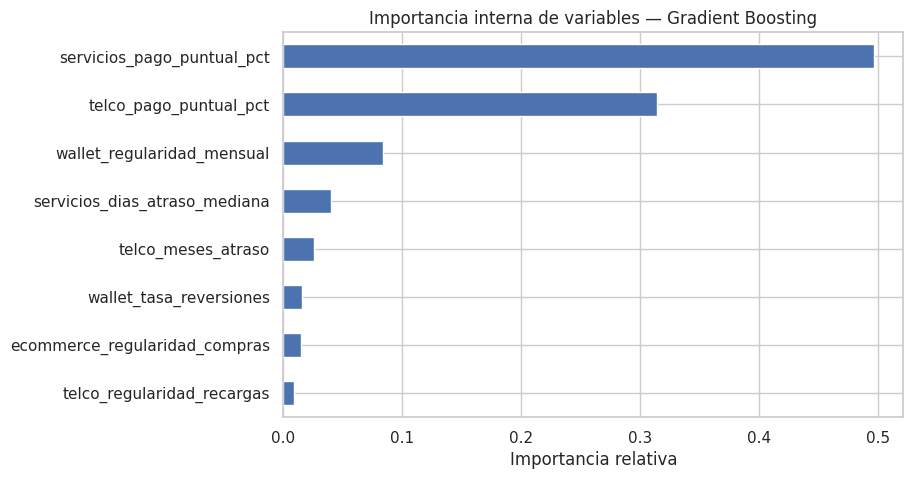

In [ ]:
# Importancias de variables del modelo oficial, si se trata de un modelo basado en árboles.
estimador_elegido = modelo_elegido.named_steps["modelo"]

if hasattr(estimador_elegido, "feature_importances_"):
    importancia = pd.Series(
        estimador_elegido.feature_importances_, index=FEATURES_MODELO
    ).sort_values(ascending=True)
    importancia.plot.barh(figsize=(8, 5))
    plt.title("Importancia interna de variables — Gradient Boosting")
    plt.xlabel("Importancia relativa")
    plt.show()
else:
    print("El estimador elegido no expone feature_importances_.")

## 15. Score demostrativo

Se transforma la probabilidad sintética de incumplimiento estimada por el candidato oficial en un score ilustrativo de 300 a 850. La transformación es únicamente didáctica: no ha sido calibrada con pérdidas observadas, costos de error, política de riesgo ni regulación de VFG. No constituye una regla de aprobación o rechazo.

In [ ]:
def score_demostrativo(probabilidad):
    return int(np.clip(np.rint(850 - 550 * float(probabilidad)), 300, 850))


def categoria_demostrativa(probabilidad):
    if probabilidad < 0.10:
        return "Bajo (ilustrativo)"
    if probabilidad < 0.25:
        return "Medio (ilustrativo)"
    return "Alto (ilustrativo)"


muestra = datos_12.loc[indices_test[:10], FEATURES_MODELO].copy()
prob_muestra = modelo_elegido.predict_proba(muestra)[:, 1]
resultado_scoring = pd.DataFrame({
    "id_solicitud": datos_12.loc[indices_test[:10], "id_solicitud"].values,
    "probabilidad_sintetica": prob_muestra,
    "score_demostrativo": [score_demostrativo(p) for p in prob_muestra],
    "categoria_demostrativa": [categoria_demostrativa(p) for p in prob_muestra],
})
display(resultado_scoring.round(4))

,id_solicitud,probabilidad_sintetica,score_demostrativo,categoria_demostrativa
0,AUR-003403,0.9684,317,Alto (ilustrativo)
1,AUR-003245,0.3051,682,Alto (ilustrativo)
2,AUR-003037,0.1587,763,Medio (ilustrativo)
3,AUR-009412,0.1258,781,Medio (ilustrativo)
4,AUR-005922,0.6506,492,Alto (ilustrativo)
5,AUR-005479,0.1220,783,Medio (ilustrativo)
6,AUR-006245,0.8912,360,Alto (ilustrativo)
7,AUR-001365,0.0673,813,Bajo (ilustrativo)
8,AUR-004325,0.0504,822,Bajo (ilustrativo)
9,AUR-006673,0.0508,822,Bajo (ilustrativo)


## 16. Exportación opcional del dataset único

Se exporta únicamente el dataset correspondiente al escenario de prevalencia objetivo del 12%. El CSV incluye características sintéticas, atributos de auditoría y la variable objetivo `incumplimiento_90d_12m`. Esta última debe excluirse siempre de las variables predictoras.

La exportación está desactivada por defecto. Activa `EXPORTAR_CSV = True` si necesitas generar el archivo en la carpeta de salida.

In [ ]:
from pathlib import Path

EXPORTAR_CSV = False  # Cambiar a True para guardar el archivo.
CARPETA_SALIDA = Path("salidas_aurora_score")

if EXPORTAR_CSV:
    CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)
    ruta = CARPETA_SALIDA / "aurora_score_2_0_12pct.csv"
    datos_12.to_csv(ruta, index=False, encoding="utf-8-sig")
    print("Dataset guardado:", ruta.resolve())
else:
    print("Exportación desactivada. Cambia EXPORTAR_CSV a True para generar el CSV único del 12%.")

Exportación desactivada. Cambia EXPORTAR_CSV a True para generar el CSV único del 12%.


## 17. Conclusiones y limitaciones

### Lectura de resultados

Gradient Boosting se mantiene como **candidato oficial** por coherencia con el caso de estudio y la planificación presentada por el equipo. La variante base u optimizada se selecciona únicamente con F1 de clase 1 en validación. Regresión Logística y Random Forest se mantienen como benchmarks para contextualizar el rendimiento.

La evaluación final debe leerse con todas las métricas. Un Accuracy alto puede coexistir con un Recall bajo; un Recall mayor puede aumentar los falsos positivos. F1 de clase 1 sintetiza Precision y Recall para la clase de incumplimiento, mientras que F1-macro otorga el mismo peso a ambas clases. No se debe presentar una sola métrica aislada.

Si un benchmark supera al candidato oficial en alguna métrica de prueba, la diferencia se documenta como hallazgo. No se modifica el conjunto de prueba ni se cambian etiquetas para forzar una victoria del modelo esperado.

### Limitaciones

- Las características y etiquetas son sintéticas; no reproducen datos reales de VFG ni de los cuatro países.
- El 12% es una prevalencia objetivo elegida para experimentación. No es una tasa observada de clientes morosos ni equivale al 11% de pérdida monetaria esperada de la cartera descrita en el caso.
- El mecanismo generador define las relaciones que intentan aprender los modelos. El rendimiento mide, en parte, la recuperación de reglas artificiales diseñadas por el equipo.
- La interacción moderada se introduce para estudiar el aporte potencial de Gradient Boosting; no prueba que esa interacción exista en una población real.
- La búsqueda de hiperparámetros es acotada y reproducible; no constituye una optimización exhaustiva.
- La auditoría sintética no sustituye una evaluación legal, estadística y ética con población real, representativa y obtenida lícitamente.
- Antes de una implementación real, se requiere validación temporal, calibración, explicabilidad, auditoría independiente, supervisión humana y cumplimiento regulatorio por país.

In [ ]:
print("RESUMEN DE EJECUCIÓN — AURORA SCORE 2.0")
print("Registros:", len(datos_12))
print("Predictores del modelo:", len(FEATURES_MODELO))
print("Prevalencia objetivo:", f"{PREVALENCIA_OBJETIVO:.2%}")
print("Prevalencia observada:", f"{datos_12[TARGET].mean():.2%}")
print("Candidato oficial:", modelo_elegido_nombre)
print("Umbral elegido en validación:", round(umbral_elegido, 3))
print("F1 clase 1 en validación:", round(f1_val_elegido, 4))
print("F1 clase 1 en prueba:", round(metricas_finales["f1_clase_1"], 4))
print("F1-macro en prueba:", round(metricas_finales["f1_macro"], 4))
print("Recall en prueba:", round(metricas_finales["recall_clase_1"], 4))
print("Accuracy en prueba:", round(metricas_finales["accuracy"], 4))
print("\nNotebook ejecutado. Interpretar todos los resultados dentro de las limitaciones sintéticas documentadas.")

RESUMEN DE EJECUCIÓN — AURORA SCORE 2.0
Registros: 10000
Predictores del modelo: 8
Prevalencia objetivo: 12.00%
Prevalencia observada: 12.03%
Candidato oficial: Gradient Boosting — optimizado
Umbral elegido en validación: 0.78
F1 clase 1 en validación: 0.6364
F1 clase 1 en prueba: 0.6345
F1-macro en prueba: 0.7925
Recall en prueba: 0.6266
Accuracy en prueba: 0.913

Notebook ejecutado. Interpretar todos los resultados dentro de las limitaciones sintéticas documentadas.
